In [1]:
import wikipediaapi
import pandas as pan
from collections import Counter
import matplotlib.pyplot as mat
import numpy as np
import random as ran
import tkinter as tk
from tkinter import ttk
USER_AGENT = "LanguageGuesser (brylsimons@seznam.cz)"

#moje články a jazyky co chci použít
clanky = {
    'cs': 'Česko',
    'fi': 'Suomi',
    'sk': 'Slovensko',
    'de': 'Deutschland',
    'en': 'United_States', 
}



In [2]:
#pokus s více zdroji zda se zvýší přesnost.
clanky = {
    'cs': ['Česko', 'Praha'],
    'fi': ['Suomi', 'Helsinki', 'Sauna', 'Tampere'],
    'sk': ['Slovensko', 'Bratislava', 'Vysoké_Tatry', 'Košice'],
    'de': ['Deutschland' ],
    'en': ['United_States', 'London', 'Artificial_intelligence'], 
}
korpus = {}

for jazyk, seznam_titulu in clanky.items():
    # Inicializace Wikipedia API jednou pro daný jazyk
    wiki = wikipediaapi.Wikipedia(user_agent=USER_AGENT, language=jazyk)
    vsechny_texty = []
    
    for titul in seznam_titulu:
        clanek = wiki.page(titul)
        if clanek.exists():
            # Text článku přidáme do seznamu
            vsechny_texty.append(clanek.text)
            print(f"[{jazyk}] Staženo: {titul}")
        else:
            print(f"[{jazyk}] Článek neexistuje: {titul}")
      
    # Všechny stažené články daného jazyka spojíme mezerou a převedeme na malá písmena
    korpus[jazyk] = " ".join(vsechny_texty).lower()


[cs] Staženo: Česko
[cs] Staženo: Praha
[fi] Staženo: Suomi
[fi] Staženo: Helsinki
[fi] Staženo: Sauna
[fi] Staženo: Tampere
[sk] Staženo: Slovensko
[sk] Staženo: Bratislava
[sk] Staženo: Vysoké_Tatry
[sk] Staženo: Košice
[de] Staženo: Deutschland
[en] Staženo: United_States
[en] Staženo: London
[en] Staženo: Artificial_intelligence


In [3]:
# rozdělení textu na jednoznaky dvouznaky a trojznaky (včetně mezer)
unigramy = {}
bigramy = {}
trigramy = {}
for jazyk, text in korpus.items():
    seznam_unigramy = []
    seznam_bigramy = []
    seznam_trigramy = []

    seznam_unigramy = list(text)
    for i in range(len(text)-1):
        seznam_bigramy.append(text[i:i+2])
    for r in range(len(text)-2):
        seznam_trigramy.append(text[r:r+3])
    unigramy[jazyk] = Counter(seznam_unigramy)
    bigramy[jazyk] = Counter(seznam_bigramy)
    trigramy[jazyk] = Counter(seznam_trigramy)


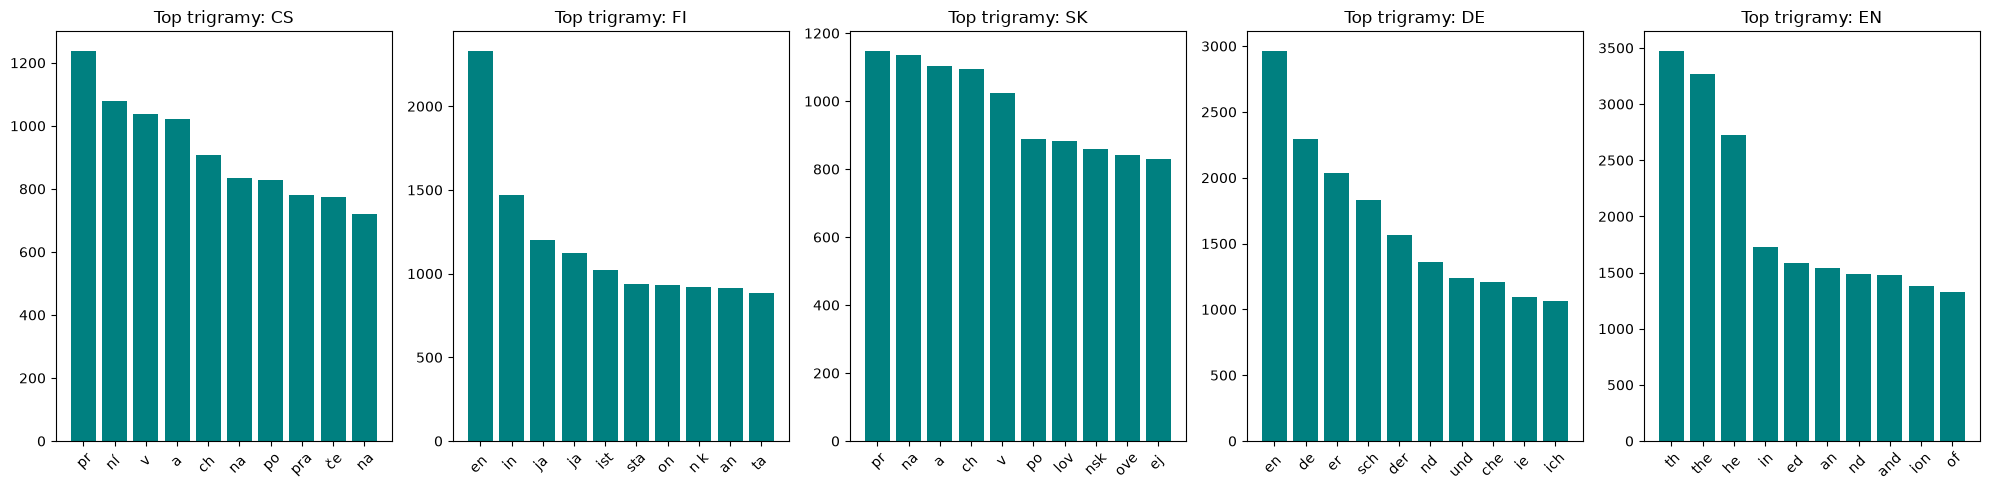

In [4]:
# graf
top10unigramy={}
top10bigramy={}
top10trigramy ={}
for jazyk in unigramy:
    top10unigramy[jazyk] = unigramy[jazyk].most_common(10)
    top10bigramy[jazyk] = bigramy[jazyk].most_common(10)
    top10trigramy[jazyk] = trigramy[jazyk].most_common(10)


fig, axes = mat.subplots(1, 5, figsize=(20,5))

for i, (jazyk, hodnoty) in enumerate(top10trigramy.items()):
    x = [polozka[0] for polozka in hodnoty]
    y = [polozka[1] for polozka in hodnoty]

    axes[i].bar(x, y, color='teal')
    axes[i].set_title(f"Top trigramy: {jazyk.upper()}")
    axes[i].tick_params(axis='x', rotation=45)
mat.tight_layout()
mat.show()

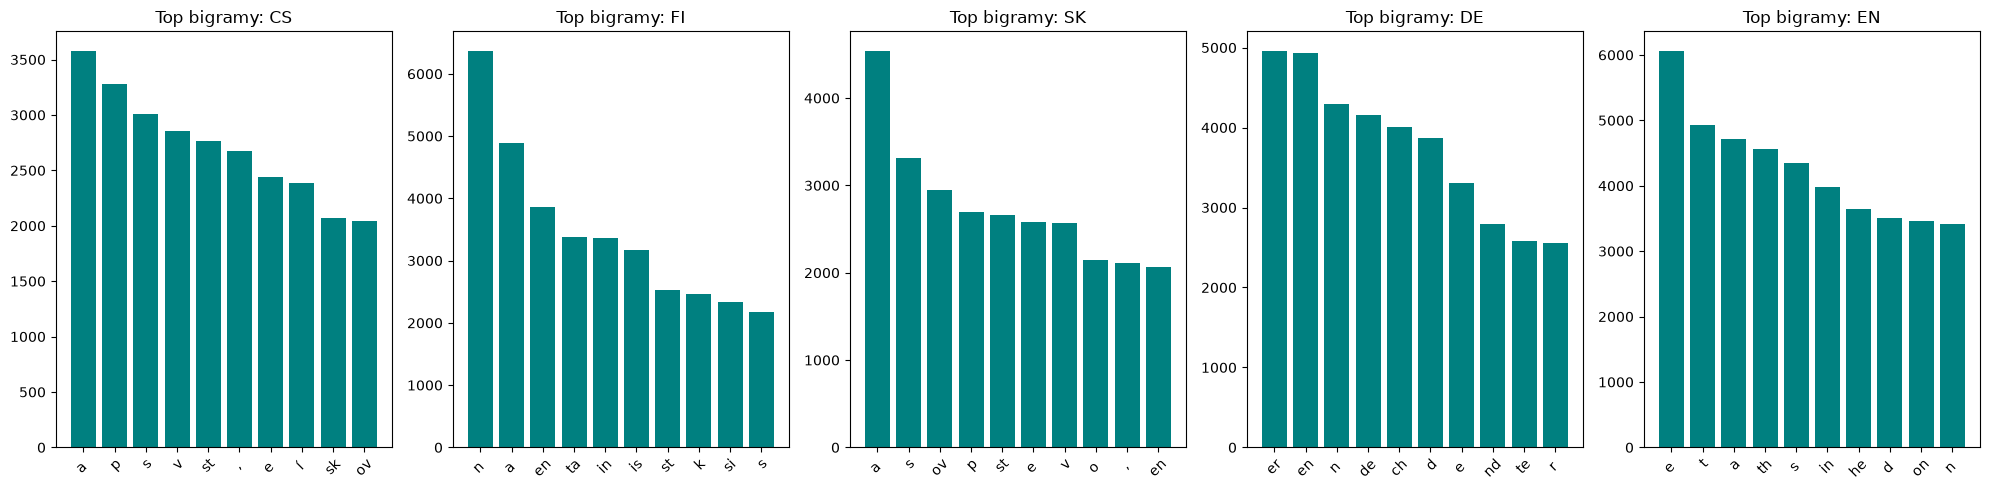

In [5]:
fig, axes = mat.subplots(1, 5, figsize=(20,5))
for i, (jazyk, hodnoty) in enumerate(top10bigramy.items()):
    x = [polozka[0] for polozka in hodnoty]
    y = [polozka[1] for polozka in hodnoty]

    axes[i].bar(x, y, color='teal')
    axes[i].set_title(f"Top bigramy: {jazyk.upper()}")
    axes[i].tick_params(axis='x', rotation=45)
mat.tight_layout()
mat.show()

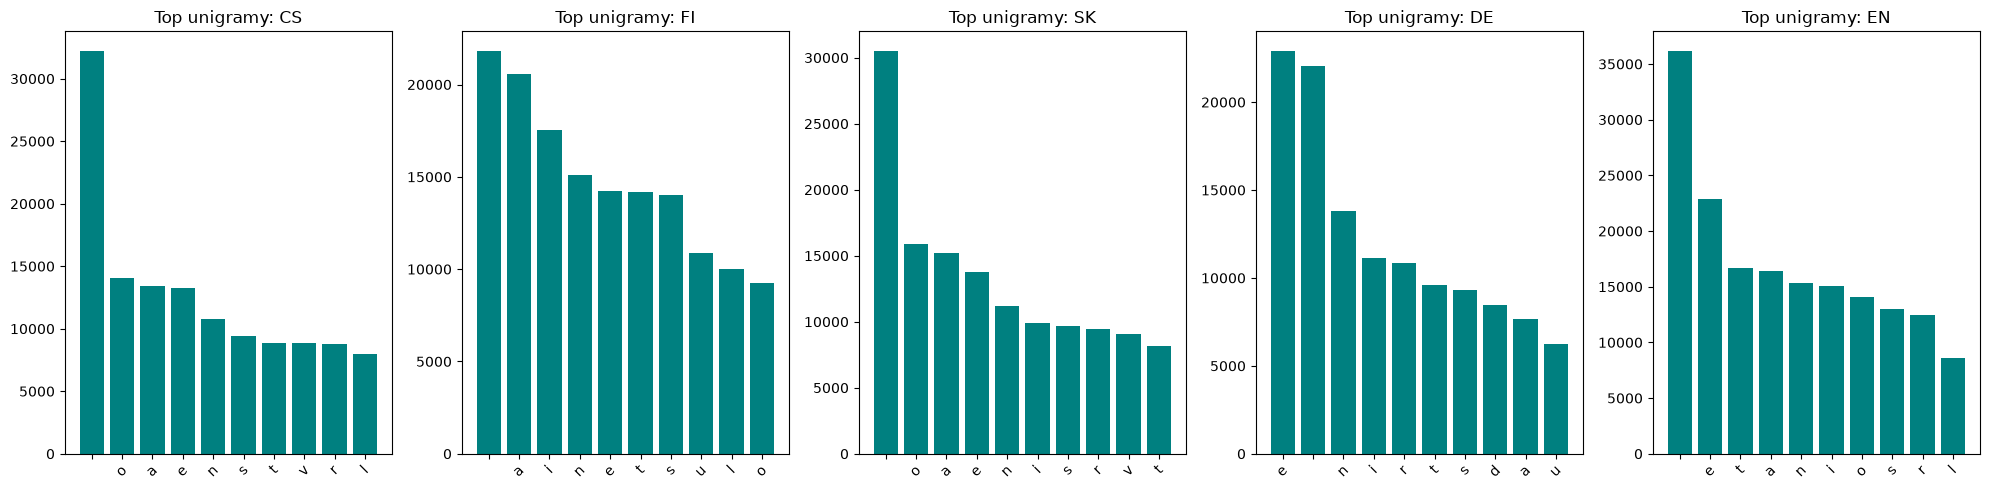

In [6]:
fig, axes = mat.subplots(1, 5, figsize=(20,5))
for i, (jazyk, hodnoty) in enumerate(top10unigramy.items()):
    x = [polozka[0] for polozka in hodnoty]
    y = [polozka[1] for polozka in hodnoty]

    axes[i].bar(x, y, color='teal')
    axes[i].set_title(f"Top unigramy: {jazyk.upper()}")
    axes[i].tick_params(axis='x', rotation=45)
mat.tight_layout()
mat.show()

In [ ]:
celkem_unigramu = {}
celkem_bigramu  = {}
celkem_trigramu = {}

min_p_uni = {}
min_p_bi  = {}
min_p_tri = {}


for jazyk in unigramy:
    celkem_unigramu[jazyk] = sum(unigramy[jazyk].values())
    min_p_uni[jazyk] = 1/celkem_unigramu[jazyk]

for jazyk in bigramy:
    celkem_bigramu[jazyk] = sum(bigramy[jazyk].values())
    min_p_bi[jazyk] = 1/celkem_bigramu[jazyk]


for jazyk in trigramy:
    celkem_trigramu[jazyk] = sum(trigramy[jazyk].values())
    min_p_tri[jazyk] = 1/celkem_trigramu[jazyk]



In [4]:
# pomocná funkce pro neopakování pozic
def pomocna (velikost, pocet, dostupne_pozice, delka, text):
    vyber =[]
    
    for _ in range(pocet):
        platne_pozice=[]
        for p in dostupne_pozice:
            if p + velikost <= delka:
                platne_pozice.append(p)
        if not platne_pozice:
            break
        #vybereme náhodně pozici
        vybrana_pozice = ran.choice(platne_pozice)
        vyber.append(text[vybrana_pozice: vybrana_pozice + velikost])
        #odstaním použitý pozice
        for i in range(vybrana_pozice, vybrana_pozice + velikost):
            if i in dostupne_pozice:
                dostupne_pozice.remove(i)

    return vyber

In [5]:
def vyber_ngramy(text, N):
    text = text.lower()
    delka = len(text)

    indexy_pozic = list(range(delka)) 

    vybrane_trigramy = pomocna(3, N, indexy_pozic, delka, text  )
    vybrane_bigramy = pomocna(2, N, indexy_pozic, delka, text  )
    vybrane_unigramy = pomocna(1, N, indexy_pozic, delka, text  )

    return vybrane_unigramy, vybrane_bigramy, vybrane_trigramy
    

In [ ]:
def predikuj_jazyk(text, N=10):
    uni, bi, tri, = vyber_ngramy(text, N)
    #váhy tri gramy více vystihují daný jazyk - zkusil jsem je přidat pro zvýšení přesnosti
    v_uni = 1.0
    v_bi = 1.5
    v_tri = 2.0
    if not uni and not bi and not tri:
        return "Text je příliš krátký", {}
    
    skore = {}
    for jazyk in unigramy.keys():
        suma_logaritmu = 0.0

        # pro uni
        for u in uni:
            pocet = unigramy[jazyk].get(u, 0)
            if pocet > 0:
                p= pocet / celkem_unigramu[jazyk]
            else:
                p=min_p_uni[jazyk]
            suma_logaritmu += v_uni*np.log(p)

                # pro bi
        for b in bi:
            pocet = bigramy[jazyk].get(b, 0)
            if pocet > 0:
                p= pocet / celkem_bigramu[jazyk]
            else:
                p=min_p_bi[jazyk]
            suma_logaritmu += v_bi*np.log(p)

                    # pro tri
        for t in tri:
            pocet = trigramy[jazyk].get(t, 0)
            if pocet > 0:
                p= pocet / celkem_trigramu[jazyk]
            else:
                p=min_p_tri[jazyk]
            suma_logaritmu += v_tri*np.log(p)

        skore[jazyk]= suma_logaritmu

    odhadovany_jazyk = max(skore, key=skore.get)
    return odhadovany_jazyk, skore

In [9]:
#testovací pokus
test_vety = {
    "Čeština": "Dnes je venku velmi příjemné počasí a odpoledne půjdeme na procházku.",
    "Slovenština": "Dnes je vonku veľmi pekné počasie a popoludní pôjdeme na prechádzku.",
    "Angličtina": "Natural language processing and machine learning algorithms are fascinating.",
    "Němčina": "Das Wetter in Berlin ist heute ziemlich kühl und es regnet seit dem Morgen.",
    "Finština": "Tämä on suomenkielinen lause ja Helsingissä sataa lunta talvella."
}


for ocekavany_jazyk, veta in test_vety.items():
    detekovany_jazyk, body = predikuj_jazyk(veta, N=15)
    print(f"Očekáváno: {ocekavany_jazyk:<12} | Detekováno: {detekovany_jazyk.upper()} | Skóre: {round(body[detekovany_jazyk], 2)}")

Očekáváno: Čeština      | Detekováno: CS | Skóre: -402.22
Očekáváno: Slovenština  | Detekováno: SK | Skóre: -384.42
Očekáváno: Angličtina   | Detekováno: EN | Skóre: -366.26
Očekáváno: Němčina      | Detekováno: DE | Skóre: -375.51
Očekáváno: Finština     | Detekováno: FI | Skóre: -341.31


In [ ]:
nazvy_jazyku = {
    'cs': 'Čeština (Czech)',
    'sk': 'Slovenština (Slovak)',
    'en': 'Angličtina (English)',
    'de': 'Němčina (German)',
    'fi': 'Finština (Finnish)'
}

# Inicializace hlavního okna
okno = tk.Tk()
okno.title("Detektor jazyka (Naivní Bayes)")
okno.geometry("620x620")
okno.resizable(False, False)

# Vstupní pole pro text
popisek_text = tk.Label(okno, text="Zadejte nebo vložte text pro analýzu:", font=("Arial", 10, "bold"))
popisek_text.pack(anchor="w", padx=20, pady=(15, 5))

text_vstup = tk.Text(okno, height=6, width=65, font=("Arial", 10))
text_vstup.pack(padx=20, pady=5)

# Posuvník pro parametr N
ramecek_slider = tk.Frame(okno)
ramecek_slider.pack(fill="x", padx=20, pady=10)

popisek_n = tk.Label(ramecek_slider, text="Počet vzorků (N): 15", font=("Arial", 10))
popisek_n.pack(side="left")

def aktualizuj_popisek_slideru(hodnota):
    popisek_n.config(text=f"Počet vzorků (N): {int(float(hodnota))}")

slider_n = ttk.Scale(
    ramecek_slider,
    from_=1,
    to=50,
    orient="horizontal",
    command=aktualizuj_popisek_slideru
)
slider_n.set(15)
slider_n.pack(side="right", fill="x", expand=True, padx=(10, 0))

#Textová oblast pro výstup
popisek_vystup = tk.Label(okno, text="Výsledky analýzy:", font=("Arial", 10, "bold"))
popisek_vystup.pack(anchor="w", padx=20, pady=(10, 5))

vystup_text = tk.Text(okno, height=12, width=65, state="disabled", font=("Consolas", 10), bg="#f5f5f5")
vystup_text.pack(padx=20, pady=5)

#Logika po kliknutí na tlačítko
def po_kliknuti():
    zadany_text = text_vstup.get("1.0", tk.END).strip()
    n_hodnota = int(slider_n.get())

    # Odemkneme výstupní pole pro zápis a smažeme předchozí obsah
    vystup_text.config(state="normal")
    vystup_text.delete("1.0", tk.END)

    if not zadany_text:
        vystup_text.insert(tk.END, "Zadejte prosím nějaký text.\n")
        vystup_text.config(state="disabled")
        return

    # Volání klasifikační funkce
    kod_jazyka, skore = predikuj_jazyk(zadany_text, N=n_hodnota)

    plny_nazev = nazvy_jazyku.get(kod_jazyka, kod_jazyka)
    zebricek = sorted(skore.items(), key=lambda x: x[1], reverse=True)

   
    vystup_text.insert(tk.END, f"Detekovaný jazyk: {plny_nazev}\n")
    vystup_text.insert(tk.END, f"Skóre vítěze:     {round(skore[kod_jazyka], 2)}\n")
    vystup_text.insert(tk.END, "-" * 55 + "\n")
    vystup_text.insert(tk.END, "Kompletní pořadí pravděpodobnosti:\n")
    
    for kod, sk in zebricek:
        jazyk_popis = nazvy_jazyku.get(kod, kod)
        vystup_text.insert(tk.END, f"  {jazyk_popis:<26} | skóre: {round(sk, 2):>8.2f}\n")

    # Zamkneme výstupní pole aby nešlo přepsat
    vystup_text.config(state="disabled")

# Tlačítko pro spuštění
tlacitko = tk.Button(
    okno,
    text="Detekovat jazyk",
    command=po_kliknuti,
    bg="#007acc",
    fg="white",
    font=("Arial", 10, "bold"),
    padx=10,
    pady=5
)
tlacitko.pack(pady=10)

#Spuštění smyčky aplikace
okno.mainloop()

In [ ]:
testovaci_sada = [
    # (Text, Očekávaný kód, Kategorie)
    ("Dnes odpoledne půjdeme na procházku do lesa.", "cs", "Běžná věta"),
    ("Dnes popoludní pôjdeme na prechádzku do lesa.", "sk", "Běžná věta"),
    ("Natural language processing is fascinating.", "en", "Běžná věta"),
    ("Das Wetter in den Bergen ist heute schön.", "de", "Běžná věta"),
    ("Helsinki on kaunis kaupunki talvella.", "fi", "Běžná věta"),
    ("Vlak má zpoždění.", "cs", "Krátký text"),
    ("Vlak mešká.", "sk", "Krátký text"),
    ("The train is late.", "en", "Krátký text"),
    ("Der Zug hat Verspätung.", "de", "Krátký text"),
    ("Juna on myöhässä.", "fi", "Krátký text"),
    ("Software pro management funguje online.", "cs", "Cizí slova"),
   ("Das neue Update für das Smartphone beinhaltet viele coole Features.", "de", "Cizí slova"),
]